# TP 2 — Paneles solares: exploración y preprocesamiento

**Procesamiento de Imágenes**

Integrantes: _(completar)_

---

Este notebook deja el dataset listo: primero se mira qué hay (exploración) y después
se limpian las etiquetas y se arman tres divisiones train / val por fuente (preprocesamiento).

| Sección | Contenido |
|---|---|
| 1 | Exploración de los datos |
| 2 | Limpieza de etiquetas y splits por fuente |

Las rutas son relativas a la raíz del repositorio (`data/raw/`, `data/splits/`, `data/yolo/`),
así el notebook funciona al clonarlo.


## 0. Preparación del entorno

El notebook se ejecuta desde la raíz del repositorio clonado. Las imágenes y las
etiquetas originales están en `data/raw/`. Los splits quedan en `data/splits/` y el
layout de YOLO en `data/yolo/`. Los gráficos se muestran en el notebook y no se exportan.


In [15]:
import random, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white",
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Rutas relativas a la raíz del repo. No se resuelven a absolutas: así clonar y correr alcanza.
RAIZ = Path(".")
DIR_IMG = RAIZ / "data" / "raw" / "images"
DIR_LAB = RAIZ / "data" / "raw" / "labels"
DIR_SPLITS = RAIZ / "data" / "splits"
DIR_YOLO_ROOT = RAIZ / "data" / "yolo"
if not DIR_IMG.is_dir() or not DIR_LAB.is_dir():
    raise FileNotFoundError(
        "No encontré data/raw/images y data/raw/labels. "
        "Ejecutá el notebook desde la raíz del repositorio clonado.")

print(f"datos   : {DIR_IMG.as_posix()} | {DIR_LAB.as_posix()}")
print(f"splits  : {DIR_SPLITS.as_posix()}")
print(f"yolo    : {DIR_YOLO_ROOT.as_posix()}")
print(f"imágenes: {len(list(DIR_IMG.glob('*.png')))} | etiquetas: {len(list(DIR_LAB.glob('*.txt')))}")


datos   : data/raw/images | data/raw/labels
splits  : data/splits
yolo    : data/yolo
imágenes: 900 | etiquetas: 900


---
## 1. Exploración de los datos

Qué hay, cuánto hay de cada cosa, cómo son las imágenes y las cajas.
Las clases 1 y 2 no son paneles: no entran en los conteos y, en el preprocesamiento,
se elimina esa fila del `.txt`.


In [16]:
def grupo_de(nombre: str) -> str:
    """Los nombres de archivo delatan de qué fuente viene cada imagen."""
    if nombre.startswith("PV01"):           return "PV01"
    if nombre.startswith("solarpanels_hd"): return "solarpanels_hd"
    if nombre.startswith("kingston2"):      return "kingston2"
    if nombre.startswith("kingston_"):      return "kingston"
    return "geo_unknown"


def leer_yolo(ruta):
    """Lee un .txt en formato YOLO -> lista de (clase, cx, cy, w, h) normalizados."""
    cajas = []
    for linea in Path(ruta).read_text().splitlines():
        if not linea.strip():
            continue
        partes = linea.split()
        cajas.append((int(float(partes[0])), *map(float, partes[1:5])))
    return cajas


# Clases 1 y 2 no son paneles. Si un .txt sólo tiene esas filas, la imagen es negativa.
CLASES_NEGATIVAS = {1, 2}


def es_panel(cls):
    return cls not in CLASES_NEGATIVAS


# Inventario: una fila por imagen. n_cajas y tiene_paneles miran sólo la clase 0.
filas = []
for p in sorted(DIR_IMG.glob("*.png")):
    with Image.open(p) as im:
        ancho, alto, modo = im.width, im.height, im.mode
    todas = leer_yolo(DIR_LAB / (p.stem + ".txt"))
    cajas = [c for c in todas if es_panel(c[0])]
    filas.append(dict(nombre=p.stem, grupo=grupo_de(p.stem), ancho=ancho, alto=alto,
                      modo=modo, n_cajas=len(cajas), tiene_paneles=int(len(cajas) > 0),
                      clases=sorted({c[0] for c in todas}),
                      n_descartadas=sum(1 for c in todas if not es_panel(c[0]))))
inv = pd.DataFrame(filas)

# Una fila por caja de panel (clase 0). Las clases 1 y 2 quedan aparte.
filas_cajas, filas_descartadas = [], []
for p in sorted(DIR_LAB.glob("*.txt")):
    for cls, cx, cy, w, h in leer_yolo(p):
        fila = dict(nombre=p.stem, grupo=grupo_de(p.stem), clase=cls,
                    cx=cx, cy=cy, w=w, h=h, area=w * h,
                    w_px=w * 256, h_px=h * 256)
        (filas_cajas if es_panel(cls) else filas_descartadas).append(fila)
cajas_df = pd.DataFrame(filas_cajas)
cajas_descartadas = pd.DataFrame(filas_descartadas)

print("imágenes totales .......... %d" % len(inv))
print("  con paneles ............. %d  (%.1f %%)" % (inv.tiene_paneles.sum(), 100 * inv.tiene_paneles.mean()))
print("  sin paneles ............. %d  (%.1f %%)" % ((1 - inv.tiene_paneles).sum(), 100 * (1 - inv.tiene_paneles.mean())))
print("cajas totales ............. %d" % len(cajas_df))
print("cajas por imagen .......... media %.2f | mediana %.0f | máx %d"
      % (inv.n_cajas.mean(), inv.n_cajas.median(), inv.n_cajas.max()))
inv.head()


imágenes totales .......... 900
  con paneles ............. 805  (89.4 %)
  sin paneles ............. 95  (10.6 %)
cajas totales ............. 4135
cajas por imagen .......... media 4.59 | mediana 2 | máx 40


,nombre,grupo,ancho,alto,modo,n_cajas,tiene_paneles,clases,n_descartadas
0,2161488_unknown_17.969541515267093_-76.7934515...,geo_unknown,256,256,P,0,0,[],0
1,2161576_unknown_18.02672120400235_-76.83812296...,geo_unknown,256,256,P,0,0,[],0
2,2161719_unknown_17.97698301995914_-76.77939693...,geo_unknown,256,256,P,0,0,[],0
3,2162024_unknown_17.982368965337454_-76.8237083...,geo_unknown,256,256,P,0,0,[],0
4,2162026_unknown_17.98517847101532_-76.82798278...,geo_unknown,256,256,P,0,0,[],0


### 1.1 Chequeos de integridad

Vale la pena mirar esto antes de entrenar: si el dataset tiene rarezas, los modelos las aprenden.

In [17]:
print("— tamaños de imagen —")
print(inv.groupby(["ancho", "alto"]).size().to_string())

print("\n— modos de color de los PNG —")
print(inv.modo.value_counts().to_string())
print("  ('P' = paleta indexada, no RGB: hay que convertirlos al cargarlos)")

print("\n— ids de clase en los .txt originales —")
print("  clase 0 (panel): %d cajas" % len(cajas_df))
if len(cajas_descartadas):
    print(cajas_descartadas.clase.value_counts().sort_index().rename("filas a eliminar").to_string())
anomalas = inv[inv.n_descartadas > 0]
print("\n  las clases 1 y 2 no son paneles: se elimina esa fila del .txt (%d filas en %d archivos)."
      % (len(cajas_descartadas), len(anomalas)))
for n in anomalas.nombre:
    queda = "sigue positiva" if inv.set_index("nombre").loc[n, "tiene_paneles"] else "queda negativa"
    print("    %s  (%s)" % (n, queda))
print("  → si después de borrarlas el .txt queda vacío, la imagen es un caso negativo.")

x1 = cajas_df.cx - cajas_df.w / 2
y1 = cajas_df.cy - cajas_df.h / 2
x2 = cajas_df.cx + cajas_df.w / 2
y2 = cajas_df.cy + cajas_df.h / 2
exceso = np.maximum.reduce([-x1.values, -y1.values, x2.values - 1, y2.values - 1])
print("\n— cajas que se salen de [0,1] —")
for tol in (0.0, 1e-6, 1e-3):
    print("    con exceso > %-6g : %4d cajas" % (tol, int((exceso > tol).sum())))
print("    exceso máximo: %.1e  (= %.5f px sobre 256)" % (exceso.max(), 256 * exceso.max()))
print("  → el desborde es de medio millonésimo: es el redondeo a 6 decimales del formato, no un")
print("    error de anotación. Recortamos igual porque no cuesta nada y evita warnings.")
print("\n— cajas degeneradas (w o h = 0): %d" % int(((cajas_df.w <= 0) | (cajas_df.h <= 0)).sum()))


— tamaños de imagen —
ancho  alto
256    256     900

— modos de color de los PNG —
modo
RGB    868
P       32
  ('P' = paleta indexada, no RGB: hay que convertirlos al cargarlos)

— ids de clase en los .txt originales —
  clase 0 (panel): 4135 cajas
clase
1    1
2    6

  las clases 1 y 2 no son paneles: se elimina esa fila del .txt (7 filas en 6 archivos).
    solarpanels_hd_1__x0_16473_y0_15637_dxdy_832_0_1  (sigue positiva)
    solarpanels_hd_1__x0_17127_y0_21975_dxdy_832_3_2  (queda negativa)
    solarpanels_hd_1__x0_18698_y0_21896_dxdy_832_3_2  (queda negativa)
    solarpanels_hd_2__x0_10179_y0_13259_dxdy_832_3_3  (queda negativa)
    solarpanels_hd_3__x0_12952_y0_27220_dxdy_832_3_3  (queda negativa)
    solarpanels_hd_3__x0_13451_y0_27491_dxdy_832_2_0  (queda negativa)
  → si después de borrarlas el .txt queda vacío, la imagen es un caso negativo.

— cajas que se salen de [0,1] —
    con exceso > 0      :   79 cajas
    con exceso > 1e-06  :    0 cajas
    con exceso > 0.001  : 

### 1.2 Composición por fuente

Los nombres de archivo muestran que el dataset es un **collage de varias fuentes**. Esto resulta
ser lo más importante de toda la exploración, así que lo miramos con cuidado.

In [18]:
resumen = (inv.groupby("grupo")
             .agg(imagenes=("nombre", "size"), con_paneles=("tiene_paneles", "sum"), cajas=("n_cajas", "sum"))
             .assign(sin_paneles=lambda d: d.imagenes - d.con_paneles,
                     pct_positivas=lambda d: (100 * d.con_paneles / d.imagenes).round(1),
                     cajas_por_img=lambda d: (d.cajas / d.imagenes).round(2))
             [["imagenes", "con_paneles", "sin_paneles", "pct_positivas", "cajas", "cajas_por_img"]]
             .sort_values("imagenes", ascending=False))
print(resumen.to_string())
print("\nTOTAL: %d imágenes, %d positivas, %d cajas" % (len(inv), inv.tiene_paneles.sum(), len(cajas_df)))

                imagenes  con_paneles  sin_paneles  pct_positivas  cajas  cajas_por_img
grupo                                                                                  
PV01                 478          477            1           99.8   3556           7.44
solarpanels_hd       316          284           32           89.9    500           1.58
geo_unknown           44           10           34           22.7     13           0.30
kingston              34           34            0          100.0     66           1.94
kingston2             28            0           28            0.0      0           0.00

TOTAL: 900 imágenes, 805 positivas, 4135 cajas


El prior de clase **cambia muchísimo según la fuente**: `kingston2` es 0 % positiva y
`geo_unknown` 22.7 %, mientras que `PV01` (99.8 %), `kingston` (100 %) y `solarpanels_hd` (89.9 %)
son casi todas positivas. Dicho de otro modo: `kingston2` y `geo_unknown` son el 8 % del dataset
pero aportan 62 de las 95 negativas, y cada fuente tiene además un aspecto visual propio
(resolución, color, tipo de terreno, hasta marcas de agua del proveedor satelital).

Consecuencia práctica: un modelo puede aprender **de qué fuente viene la imagen** en lugar de
si hay paneles. Por eso la sección 2 no mezcla las fuentes al azar: cada split deja un grupo
de fuentes entero en validación.


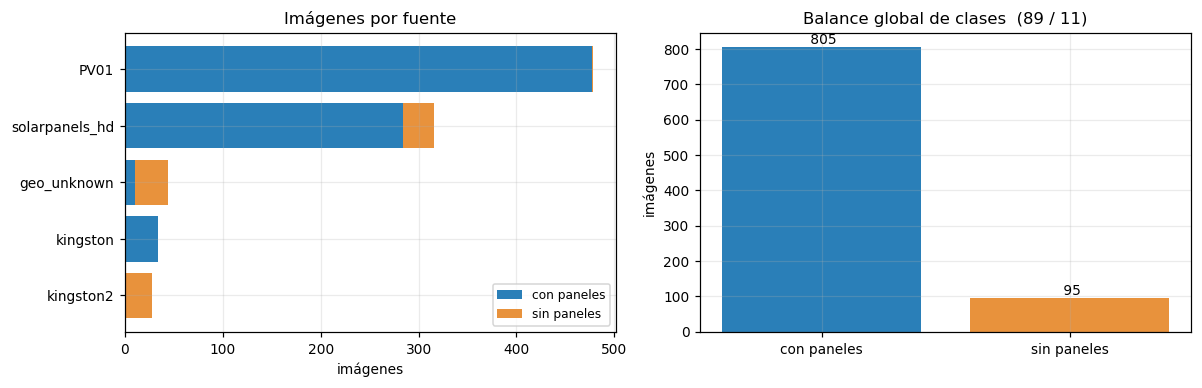

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

d = resumen.sort_values("imagenes")
axes[0].barh(d.index, d.con_paneles, label="con paneles", color="#2a7fb8")
axes[0].barh(d.index, d.sin_paneles, left=d.con_paneles, label="sin paneles", color="#e8923c")
axes[0].set_title("Imágenes por fuente")
axes[0].set_xlabel("imágenes")
axes[0].legend(fontsize=8)

conteo = [int(inv.tiene_paneles.sum()), int(len(inv) - inv.tiene_paneles.sum())]
axes[1].bar(["con paneles", "sin paneles"], conteo, color=["#2a7fb8", "#e8923c"])
axes[1].set_title("Balance global de clases  (%.0f / %.0f)"
                  % (100 * inv.tiene_paneles.mean(), 100 * (1 - inv.tiene_paneles.mean())))
axes[1].set_ylabel("imágenes")
for i, v in enumerate(conteo):
    axes[1].text(i, v, " %d" % v, ha="center", va="bottom")

plt.tight_layout()
plt.show()

### 1.3 Cuántos paneles por imagen, y de qué tamaño

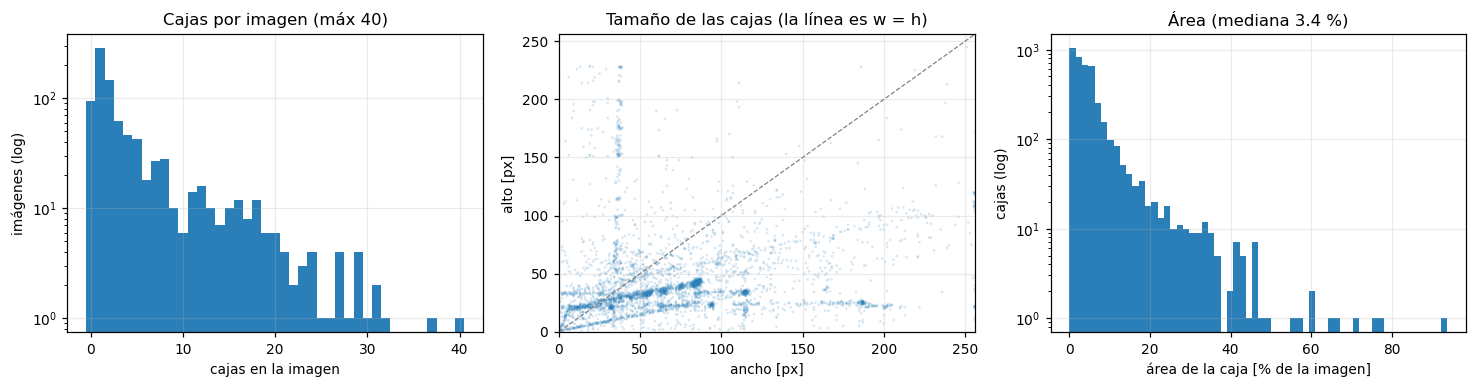

           w_px      h_px      area
count  4135.000  4135.000  4135.000
mean     72.913    43.951     0.053
std      52.208    36.434     0.070
min       1.000     1.000     0.000
5%        9.000     9.000     0.002
25%      35.000    23.000     0.015
50%      63.000    34.000     0.034
75%      95.000    50.000     0.060
95%     187.000   115.785     0.175
max     256.000   256.000     0.938

relación de aspecto w/h: mediana 1.78 → los paneles son típicamente rectángulos apaisados
cajas con algún lado < 16 px (objetos muy chicos): 639 (15.5 %)


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))

axes[0].hist(inv.n_cajas, bins=np.arange(0, inv.n_cajas.max() + 2) - 0.5, color="#2a7fb8")
axes[0].set_yscale("log")
axes[0].set_xlabel("cajas en la imagen")
axes[0].set_ylabel("imágenes (log)")
axes[0].set_title("Cajas por imagen (máx %d)" % inv.n_cajas.max())

axes[1].scatter(cajas_df.w_px, cajas_df.h_px, s=3, alpha=0.18, color="#2a7fb8", edgecolors="none")
axes[1].plot([0, 256], [0, 256], "--", lw=0.8, color="gray")
axes[1].set_xlabel("ancho [px]")
axes[1].set_ylabel("alto [px]")
axes[1].set_title("Tamaño de las cajas (la línea es w = h)")
axes[1].set_xlim(0, 256)
axes[1].set_ylim(0, 256)

axes[2].hist(100 * cajas_df.area, bins=60, color="#2a7fb8")
axes[2].set_yscale("log")
axes[2].set_xlabel("área de la caja [% de la imagen]")
axes[2].set_ylabel("cajas (log)")
axes[2].set_title("Área (mediana %.1f %%)" % (100 * cajas_df.area.median()))

plt.tight_layout()
plt.show()

print(cajas_df[["w_px", "h_px", "area"]].describe(percentiles=[.05, .25, .5, .75, .95]).round(3).to_string())
print("\nrelación de aspecto w/h: mediana %.2f → los paneles son típicamente rectángulos apaisados"
      % (cajas_df.w / cajas_df.h).median())
chicas = (cajas_df.w_px < 16) | (cajas_df.h_px < 16)
print("cajas con algún lado < 16 px (objetos muy chicos): %d (%.1f %%)"
      % (int(chicas.sum()), 100 * chicas.mean()))

### 1.4 Dónde caen los paneles dentro de la imagen

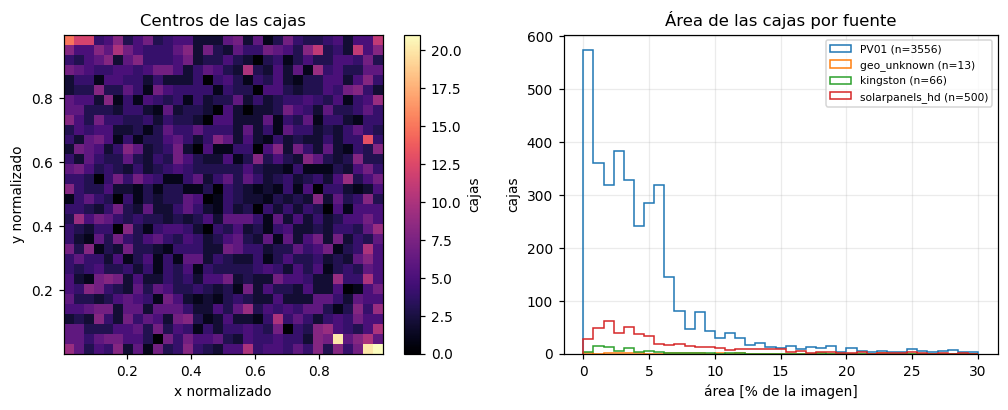

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))

h2d = axes[0].hist2d(cajas_df.cx, 1 - cajas_df.cy, bins=32, cmap="magma")
axes[0].set_title("Centros de las cajas")
axes[0].set_xlabel("x normalizado")
axes[0].set_ylabel("y normalizado")
axes[0].set_aspect("equal")
axes[0].grid(False)
plt.colorbar(h2d[3], ax=axes[0], label="cajas")

for g, sub in cajas_df.groupby("grupo"):
    axes[1].hist(100 * sub.area, bins=np.linspace(0, 30, 40), histtype="step", lw=1.4,
                 label="%s (n=%d)" % (g, len(sub)))
axes[1].set_xlabel("área [% de la imagen]")
axes[1].set_ylabel("cajas")
axes[1].set_title("Área de las cajas por fuente")
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

### 1.5 Mirar las imágenes con las cajas dibujadas

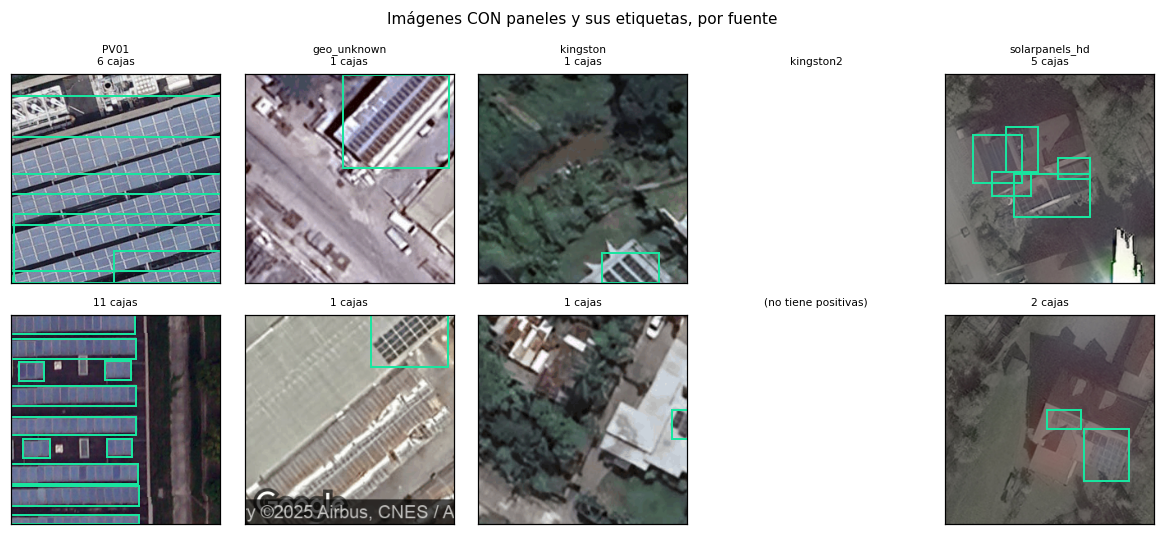

In [22]:
def cargar_rgb(nombre):
    """Carga una imagen como RGB uint8 (convierte las de paleta indexada)."""
    with Image.open(DIR_IMG / (nombre + ".png")) as im:
        return np.array(im.convert("RGB"))


def dibujar(ax, nombre, cajas=None, titulo=None, color="#19e6a0"):
    img = cargar_rgb(nombre)
    ax.imshow(img)
    if cajas is None:
        cajas = [c for c in leer_yolo(DIR_LAB / (nombre + ".txt")) if es_panel(c[0])]
    alto, ancho = img.shape[:2]
    for c in cajas:
        cx, cy, w, h = (c[1:5] if len(c) == 5 else c[:4])
        ax.add_patch(Rectangle(((cx - w / 2) * ancho, (cy - h / 2) * alto), w * ancho, h * alto,
                               fill=False, lw=1.3, edgecolor=color))
    ax.set_title(titulo if titulo is not None else "%d cajas" % len(cajas), fontsize=7)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)


n_cajas_de = inv.set_index("nombre").n_cajas
rng = np.random.default_rng(SEED)
grupos = sorted(inv.grupo.unique())

fig, axes = plt.subplots(2, len(grupos), figsize=(2.15 * len(grupos), 4.8))
for j, g in enumerate(grupos):
    pos = inv[(inv.grupo == g) & (inv.tiene_paneles == 1)].nombre.tolist()
    elegidas = list(rng.choice(pos, size=min(2, len(pos)), replace=False)) if pos else []
    for i in range(2):
        ax = axes[i, j]
        if i < len(elegidas):
            n = elegidas[i]
            enc = ("%s\n%d cajas" % (g, n_cajas_de[n])) if i == 0 else ("%d cajas" % n_cajas_de[n])
            dibujar(ax, n, titulo=enc)
        else:
            ax.set_title(g if i == 0 else "(no tiene positivas)", fontsize=7)
            ax.axis("off")
fig.suptitle("Imágenes CON paneles y sus etiquetas, por fuente", y=1.0, fontsize=10)
plt.tight_layout()
plt.show()


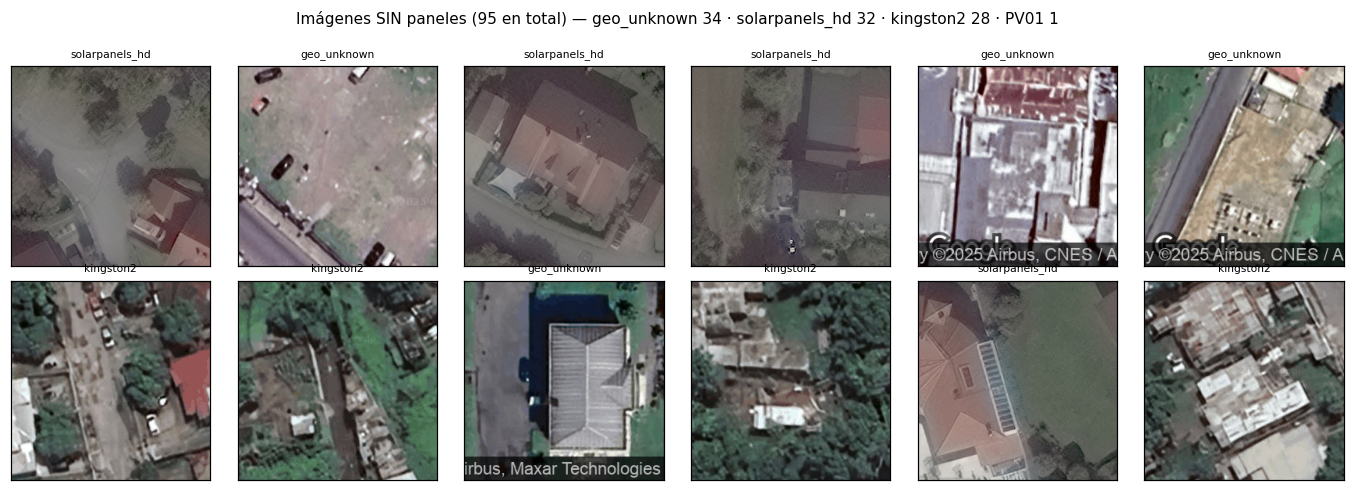

In [23]:
negs = inv[inv.tiene_paneles == 0]
elegidas = negs.sample(min(12, len(negs)), random_state=SEED).nombre.tolist()
fig, axes = plt.subplots(2, 6, figsize=(12.5, 4.4))
for ax, n in zip(axes.ravel(), elegidas):
    dibujar(ax, n, titulo=grupo_de(n))
for ax in axes.ravel()[len(elegidas):]:
    ax.axis("off")
reparto = " · ".join("%s %d" % (g, c) for g, c in negs.grupo.value_counts().items())
fig.suptitle("Imágenes SIN paneles (%d en total) — %s" % (len(negs), reparto), y=1.0, fontsize=10)
plt.tight_layout()
plt.show()

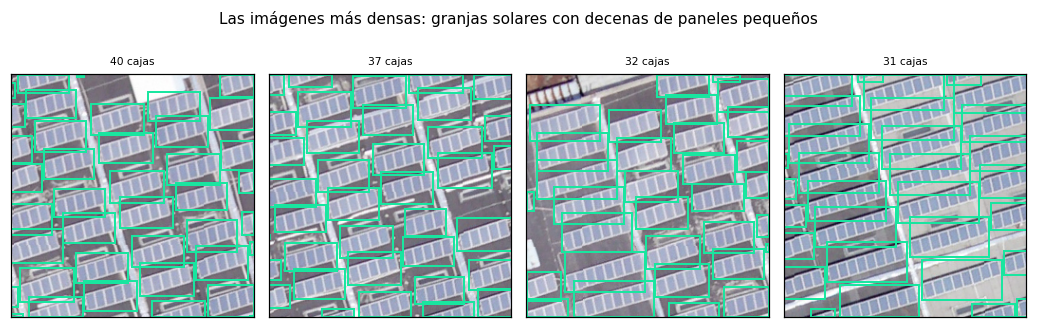

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.8))
for ax, n in zip(axes, inv.nlargest(4, "n_cajas").nombre):
    dibujar(ax, n)
fig.suptitle("Las imágenes más densas: granjas solares con decenas de paneles pequeños",
             y=1.05, fontsize=10)
plt.tight_layout()
plt.show()

### 1.6 Qué nos llevamos de la exploración

1. **900 imágenes** de 256×256 px: **805 con paneles y 95 sin paneles** (89 / 11), contando
   como positiva sólo a la que tiene al menos una caja de clase 0. Un clasificador que responda
   siempre *"hay paneles"* ya acierta cerca del 89 %. La accuracy sola no alcanza; hay que mirar
   precision / recall / F1 sobre la clase minoritaria.
2. **4135 cajas** de panel, mediana de 2 por imagen pero con cola larga (hasta 40). Tamaño
   mediano ≈ 63 × 34 px sobre 256, o sea ~3 % del área: son **objetos chicos y apaisados**.
3. El dataset es un **collage de 5 fuentes** con prior de clase muy distinto (`kingston2` 0 %
   positiva, `PV01` 99.8 %) y con aspecto visual distinguible entre fuentes. El atajo
   "reconocer la fuente en lugar del panel" está disponible. Los splits de la sección 2 dejan
   fuentes enteras en validación para medir qué pasa cuando el modelo no vio esa fuente.
4. Rarezas: **7 filas con id de clase 1 o 2** (no son paneles: se borran del `.txt`; 5 imágenes
   quedan negativas y 1 sigue positiva porque también tiene cajas de clase 0) y **32 PNG en modo
   paleta** en vez de RGB (hay que convertirlos al cargarlos). Las cajas que "se salen" del marco
   lo hacen por ~5·10⁻⁷ — redondeo a 6 decimales — y se recortan por prolijidad.


---
## 2. Limpieza de etiquetas y splits por fuente

Tres splits. En cada uno, un grupo de fuentes queda entero en validación y el resto en train:

| Split | Train | Validación |
|---|---|---|
| `solarpanels_val` | PV01, geo_unknown, kingston, kingston2 | solarpanels_hd |
| `geo_kingston_val` | PV01, solarpanels_hd | geo_unknown, kingston, kingston2 |
| `PV01_val` | solarpanels_hd, geo_unknown, kingston, kingston2 | PV01 |

Las clases 1 y 2 no son paneles: se elimina esa fila del `.txt`. Si el archivo queda vacío,
la imagen es un caso negativo. Las cajas de clase 0 se recortan al marco `[0, 1]`.

- `data/splits/<nombre>/` guarda `train.txt`, `val.txt` y las etiquetas corregidas.
- `data/yolo/<nombre>/` es el mismo split en el layout de YOLO (`images/`, `labels/`, `data.yaml`).


In [25]:
# Fuentes que van enteras a validación. El resto de las imágenes va a train.
SPLITS = {
    "solarpanels_val": {"solarpanels_hd"},
    "geo_kingston_val": {"geo_unknown", "kingston", "kingston2"},
    "PV01_val": {"PV01"},
}


def partes_de(grupos_val):
    en_val = inv.grupo.isin(grupos_val)
    return {
        "train": inv.loc[~en_val, "nombre"].tolist(),
        "val": inv.loc[en_val, "nombre"].tolist(),
    }


def tabla_de(partes):
    marca = inv.nombre.map({n: sp for sp, nombres in partes.items() for n in nombres})
    return (inv.assign(split=marca)
              .groupby("split")
              .agg(imagenes=("nombre", "size"), con_paneles=("tiene_paneles", "sum"),
                   cajas=("n_cajas", "sum"))
              .assign(sin_paneles=lambda d: d.imagenes - d.con_paneles,
                      pct_positivas=lambda d: (100 * d.con_paneles / d.imagenes).round(1))
              .reindex(["train", "val"]))


for nombre_split, grupos_val in SPLITS.items():
    partes = partes_de(grupos_val)
    print("=== %s ===  val: %s" % (nombre_split, ", ".join(sorted(grupos_val))))
    print(tabla_de(partes).to_string())
    print()
    marca = inv.nombre.map({n: sp for sp, nombres in partes.items() for n in nombres})
    print(pd.crosstab(inv.grupo, [marca, inv.tiene_paneles]).to_string())
    print()


=== solarpanels_val ===  val: solarpanels_hd
       imagenes  con_paneles  cajas  sin_paneles  pct_positivas
split                                                          
train       584          521   3635           63           89.2
val         316          284    500           32           89.9

nombre         train      val     
tiene_paneles      0    1   0    1
grupo                             
PV01               1  477   0    0
geo_unknown       34   10   0    0
kingston           0   34   0    0
kingston2         28    0   0    0
solarpanels_hd     0    0  32  284

=== geo_kingston_val ===  val: geo_unknown, kingston, kingston2
       imagenes  con_paneles  cajas  sin_paneles  pct_positivas
split                                                          
train       794          761   4056           33           95.8
val         106           44     79           62           41.5

nombre         train      val    
tiene_paneles      0    1   0   1
grupo                       

Cada validación es una fuente (o un grupo de fuentes) que el train no vio.
`tiene_paneles` ya ignora las filas de clase 1 y 2.


In [26]:
def etiqueta_limpia(nombre):
    """Clase 0 recortada a [0, 1]. Las filas de clase 1 y 2 se descartan."""
    lineas = []
    for cls, cx, cy, w, h in leer_yolo(DIR_LAB / (nombre + ".txt")):
        if not es_panel(cls):
            continue
        a, b = cx - w / 2, cy - h / 2
        c, d = cx + w / 2, cy + h / 2
        a, b, c, d = max(0.0, a), max(0.0, b), min(1.0, c), min(1.0, d)
        if c <= a or d <= b:
            continue
        lineas.append("0 %.6f %.6f %.6f %.6f" % ((a + c) / 2, (b + d) / 2, c - a, d - b))
    return "\n".join(lineas) + ("\n" if lineas else "")


ETIQUETAS = {n: etiqueta_limpia(n) for n in inv.nombre}
descartadas = int(inv.n_descartadas.sum())
print("etiquetas corregidas: %d imágenes, %d filas de clase 1 o 2 eliminadas"
      % (len(ETIQUETAS), descartadas))

for nombre_split, grupos_val in SPLITS.items():
    partes = partes_de(grupos_val)
    dir_split = DIR_SPLITS / nombre_split
    if dir_split.exists():
        shutil.rmtree(dir_split)
    for sp, nombres in partes.items():
        (dir_split / "labels" / sp).mkdir(parents=True)
        rutas = [(DIR_IMG / (n + ".png")).as_posix() for n in nombres]
        (dir_split / ("%s.txt" % sp)).write_text("\n".join(rutas) + "\n")
        for n in nombres:
            (dir_split / "labels" / sp / (n + ".txt")).write_text(ETIQUETAS[n])
    print("%s -> %s  (train %d, val %d)"
          % (nombre_split, dir_split.as_posix(), len(partes["train"]), len(partes["val"])))


etiquetas corregidas: 900 imágenes, 7 filas de clase 1 o 2 eliminadas
solarpanels_val -> data/splits/solarpanels_val  (train 584, val 316)
geo_kingston_val -> data/splits/geo_kingston_val  (train 794, val 106)
PV01_val -> data/splits/PV01_val  (train 422, val 478)


In [27]:
# Mismo reparto, en el layout de YOLO: images/{train,val} y labels/{train,val}.
for nombre_split, grupos_val in SPLITS.items():
    partes = partes_de(grupos_val)
    dir_yolo = DIR_YOLO_ROOT / nombre_split
    if dir_yolo.exists():
        shutil.rmtree(dir_yolo)
    for sp, nombres in partes.items():
        (dir_yolo / "images" / sp).mkdir(parents=True)
        (dir_yolo / "labels" / sp).mkdir(parents=True)
        for n in nombres:
            shutil.copy(DIR_IMG / (n + ".png"), dir_yolo / "images" / sp / (n + ".png"))
            (dir_yolo / "labels" / sp / (n + ".txt")).write_text(ETIQUETAS[n])
    # path relativo a este data.yaml, no una ruta de la máquina.
    (dir_yolo / "data.yaml").write_text(
        "path: .\ntrain: images/train\nval: images/val\nnc: 1\nnames: [panel]\n")
    print(nombre_split)
    print((dir_yolo / "data.yaml").read_text().rstrip())
    for sp in ("train", "val"):
        print("  %s: %d imágenes, %d etiquetas"
              % (sp, len(list((dir_yolo / "images" / sp).glob("*.png"))),
                 len(list((dir_yolo / "labels" / sp).glob("*.txt")))))


solarpanels_val
path: .
train: images/train
val: images/val
nc: 1
names: [panel]
  train: 584 imágenes, 584 etiquetas
  val: 316 imágenes, 316 etiquetas
geo_kingston_val
path: .
train: images/train
val: images/val
nc: 1
names: [panel]
  train: 794 imágenes, 794 etiquetas
  val: 106 imágenes, 106 etiquetas
PV01_val
path: .
train: images/train
val: images/val
nc: 1
names: [panel]
  train: 422 imágenes, 422 etiquetas
  val: 478 imágenes, 478 etiquetas


In [28]:
# Chequeo: ninguna etiqueta escrita conserva clase 1 o 2, y las listas usan rutas relativas.
mal = []
for raiz_out in (DIR_SPLITS, DIR_YOLO_ROOT):
    for txt in raiz_out.rglob("*.txt"):
        if txt.parent.parent.name == "labels":
            for linea in txt.read_text().splitlines():
                if linea.strip() and int(float(linea.split()[0])) != 0:
                    mal.append(txt.as_posix())
        elif txt.name in ("train.txt", "val.txt"):
            for linea in txt.read_text().splitlines():
                if Path(linea).is_absolute():
                    mal.append(linea)
print("problemas: %d" % len(mal))
for p in mal[:8]:
    print("  ", p)


problemas: 0
